# 03 · API y autenticación

Sigue el intercambio de credenciales, aprende cómo se comprueba una sesión y consulta los contratos HTTP que ofrece la API.

[Índice del backend](README.md) · [Anterior · PostgreSQL y persistencia](02_postgresql_y_persistencia.ipynb) · [Siguiente · Ingestión, tiempo real e historial](04_ingestion_tiempo_real_e_historial.ipynb)

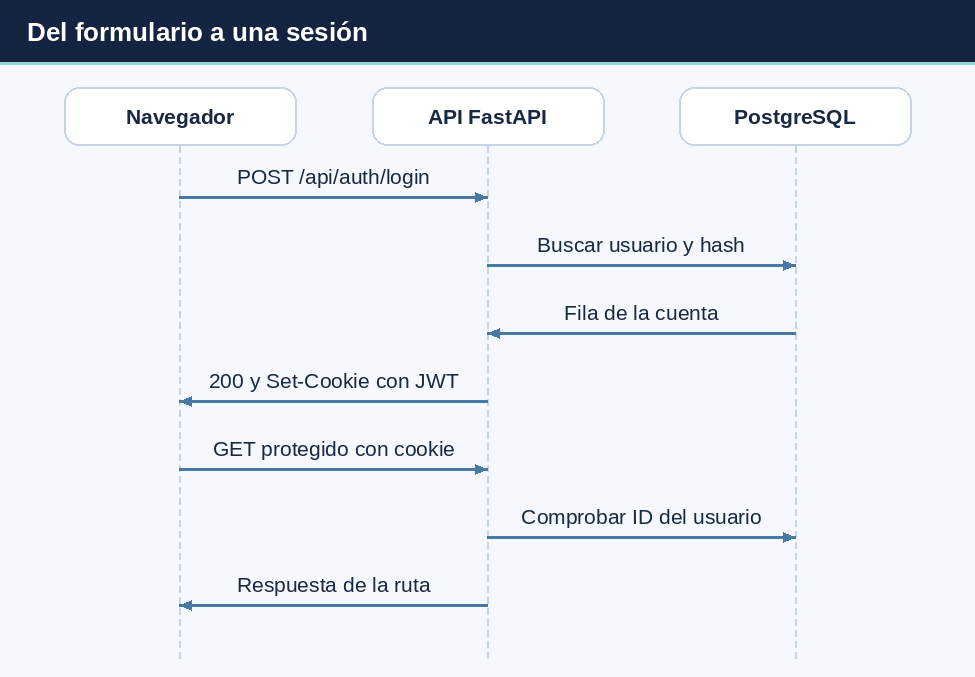

## Identidades y límites de acceso

El **rol PostgreSQL** abre la conexión con `DATABASE_URL`. El **usuario del dashboard** corresponde a una fila de `users`. El **cliente MQTT** se identifica ante el broker con `MQTT_CLIENT_ID`. Cada identidad tiene una función distinta.

La cuenta del dashboard se crea por consola con `backend.users`. La API expone inicio y cierre de sesión, consulta de la identidad actual y lectura de telemetría. Las credenciales del rol PostgreSQL no se envían al navegador ni al broker. Las rutas de telemetría requieren una sesión y devuelven únicamente datos de lectura.

## Qué hace el login con la contraseña

`POST /api/auth/login` recibe un objeto JSON con `username` y `password`. Pydantic exige cadenas con las longitudes de `Credentials`. El controlador recorta y pasa el nombre de usuario a minúsculas antes de buscarlo. La creación desde terminal exige un nombre de 3 a 64 caracteres compatible con la expresión regular del proyecto y una contraseña entre 12 y 256.

Un **hash de contraseña** deriva un resultado mediante una función diseñada para encarecer los intentos de adivinarla. Argon2 combina un valor aleatorio llamado **sal**, parámetros de coste y la contraseña. `pwdlib` guarda la información necesaria para repetir la verificación, incluyendo la sal y los parámetros. Al iniciar sesión verifica que el cálculo coincida con el hash guardado. El controlador verifica un hash ficticio si el usuario no existe. Una cuenta inexistente y una contraseña incorrecta producen el mismo mensaje genérico.

## Qué hay en un JWT

Un JWT firmado tiene tres partes separadas por puntos: encabezado, contenido y firma. La codificación Base64 URL permite leer el contenido. La firma protege su integridad. El token describe la sesión sin incluir las contraseñas.

| Campo | Valor en el backend |
| --- | --- |
| `sub` | ID de la cuenta como texto. |
| `iss` | Emisor `monitor-aire`. |
| `iat` | Instante de emisión en UTC. |
| `exp` | Caducidad calculada desde `SESSION_MINUTES`. |

El backend firma con `HS256`, un HMAC basado en SHA-256 y una clave compartida por el emisor y el verificador. `session_required` valida firma, emisor, vigencia y presencia de campos. Luego busca el usuario referenciado por `sub`. Cambiar `JWT_SECRET` invalida los tokens que se firmaron con la clave anterior.

## Cómo viaja la sesión en el navegador

Con un login correcto FastAPI devuelve `Set-Cookie` para `monitor_aire_session` y un cuerpo JSON con el nombre de usuario. El navegador conserva la cookie y la adjunta cuando coinciden el host y la ruta. En desarrollo, el proxy permite usar `/api` desde el origen del panel.

| Atributo | Efecto |
| --- | --- |
| `HttpOnly` | Impide que JavaScript lea la cookie directamente con `document.cookie`. |
| `SameSite=Strict` | Restringe su envío a solicitudes del mismo sitio. |
| `Path=/api` | Limita el ámbito a la API. |
| `Max-Age` | Expresa cuánto dura la cookie, en segundos. |
| `Secure` | Se incluye con `COOKIE_SECURE=true` y restringe el envío a conexiones seguras. |

El cierre de sesión responde `204` y borra la cookie mediante una cabecera con la misma ruta. El servidor valida vigencia y existencia de la cuenta en cada solicitud protegida nueva. La aplicación no conserva una lista de revocaciones, por lo que una copia del token sigue dependiendo de la fecha de caducidad, del secreto utilizado y del estado de la cuenta.

Un middleware responde con `Cache-Control: no-store` bajo `/api/`. Así solicita a clientes e intermediarios que no guarden esas respuestas como caché reutilizable.

## Contrato de rutas

| Método y ruta | Entradas | Respuesta |
| --- | --- | --- |
| `POST /api/auth/login` | JSON de credenciales | `200`, `username` y cookie. |
| `POST /api/auth/logout` | Ninguna requerida | `204` y eliminación de cookie. |
| `GET /api/auth/me` | Cookie | Nombre de cuenta autenticada. |
| `GET /api/live` | Cookie | Flujo de eventos `snapshot` y comentarios de heartbeat. |
| `GET /api/series` | Cookie, `device_id`, `period` opcional | Ventana, tamaño de intervalo y puntos del gráfico. |
| `GET /api/history` | Cookie, `device_id`, `start`, `end`, `page`, `per_page` | Filas, total y metadatos de paginación. |
| `GET /api/history.csv` | Cookie, `device_id`, `start`, `end` | Archivo CSV transmitido por bloques. |

`401` indica credenciales incorrectas o falta de una sesión válida. `422` indica una entrada incompatible con el contrato, como un periodo desconocido o una fecha final anterior a la inicial. `404` puede indicar una ruta que el servidor no registró. Un dispositivo sin datos puede devolver `200` con una colección vacía.

```bash
curl -i http://127.0.0.1:8000/api/auth/me
curl -i 'http://127.0.0.1:8000/api/series?device_id=ESP32_S3_0001&period=day'
```

Las solicitudes de ejemplo muestran el comportamiento sin sesión, con un `401`. Para comparar, inicia sesión en el panel y revisa estas rutas en la pestaña de red del navegador. Observa método, códigos y estructura de las respuestas sin copiar el valor de `Cookie` o `Set-Cookie`.

[Índice del backend](README.md) · [Anterior · PostgreSQL y persistencia](02_postgresql_y_persistencia.ipynb) · [Siguiente · Ingestión, tiempo real e historial](04_ingestion_tiempo_real_e_historial.ipynb)